# Benchmark Results

This notebook reproduces the benchmark figures from the paper. It evaluates three RL algorithms: **PPO**, **SAC**, **TD3** alongside three non-learning baselines: **FiPla**, **Constant**, **Random**  on the `survival-second-price-exponential` scenario (second-price auction, exponentially-distributed campaign horizon, survival value kernel).

See [`BENCHMARK.md`](BENCHMARK.md) for the full experimental protocol: scenario description, environment wrappers, training hyperparameters, and reproduction steps.

In [1]:
%matplotlib inline
from benchmark.evaluate import score_matrix
from benchmark import plots
import pandas as pd

## 1. Run benchmark

Requires pretrained models in `benchmark/models/` (see `BENCHMARK.md § Pretrained Models`). Skip this cell and go to **Section 2** if you already have a saved CSV.

**If you haven't trained a MLPValuationHead yet, run first:**

```bash
python -m benchmark.train_mlp
```

Then run the evaluation (add `--sim-policies mpc` to include MPC, which takes a few extra minutes):

In [ ]:
!python -m benchmark.evaluate --n-seeds 30

## 2. Load results

Load the saved per-step CSV and build the score matrix (total episode reward per policy per seed) used by rliable.

In [17]:
scenario_id = "survival-second-price-exponential"
date_time = "2026-04-28_11-25-46"
df_1 = pd.read_csv(f"benchmark_results/{scenario_id}_{date_time}.csv")

In [24]:
scenario_id = "survival-second-price-exponential"
date_time = "2026-04-28_11-38-54"
df_2 = pd.read_csv(f"benchmark_results/{scenario_id}_{date_time}.csv")
df_2

,policy,seed,step,t,reward,cum_reward,won,bid,payment,ctx,expected_reward,competing_bid
0,FiPla,0,1,0.113466,0.000000,0.000000,False,0.107266,0.000000,1.000000,0.000000,0.494734
1,FiPla,1,1,1.906084,0.000000,0.000000,False,0.000000,0.000000,1.000000,1.000000,0.256389
2,FiPla,1,2,4.494624,-0.400601,-0.400601,True,1.000000,0.400601,0.636307,0.000000,0.400601
3,FiPla,1,3,4.522700,1.000000,0.599399,False,0.000000,0.000000,0.636307,0.000000,0.481988
4,FiPla,1,4,5.330860,0.000000,0.599399,False,0.000000,0.000000,0.636307,0.118006,1.871850
...,...,...,...,...,...,...,...,...,...,...,...,...
8941,Shading(α=0.7),39,21,19.080889,0.000000,1.359913,False,0.000000,0.000000,0.997570,0.859727,1.902920
8942,Shading(α=0.7),39,22,20.235868,0.000000,1.359913,False,0.630000,0.000000,0.997570,0.000000,5.750457
8943,Shading(α=0.7),39,23,22.301254,0.000000,1.359913,False,0.000000,0.000000,0.997570,0.421481,0.694827
8944,Shading(α=0.7),39,24,23.148773,0.000000,1.359913,False,0.420000,0.000000,0.997570,0.077127,4.183656


In [31]:
final_df = pd.concat([df_1, df_2[(df_2["policy"] == "Shading(α=0.7)") | (df_2["policy"] == "Shading(α=0.5)") ]], ignore_index=True)
final_df

,policy,seed,step,t,reward,cum_reward,won,bid,payment,ctx,expected_reward,competing_bid
0,FiPla,0,1,0.113466,0.000000,0.000000,False,0.107266,0.000000,1.000000,0.000000,0.494734
1,FiPla,1,1,1.906084,0.000000,0.000000,False,0.000000,0.000000,1.000000,1.000000,0.256389
2,FiPla,1,2,4.494624,-0.400601,-0.400601,True,1.000000,0.400601,0.636307,0.000000,0.400601
3,FiPla,1,3,4.522700,1.000000,0.599399,False,0.000000,0.000000,0.636307,0.000000,0.481988
4,FiPla,1,4,5.330860,0.000000,0.599399,False,0.000000,0.000000,0.636307,0.118006,1.871850
...,...,...,...,...,...,...,...,...,...,...,...,...
13414,Shading(α=0.7),39,21,19.080889,0.000000,1.359913,False,0.000000,0.000000,0.997570,0.859727,1.902920
13415,Shading(α=0.7),39,22,20.235868,0.000000,1.359913,False,0.630000,0.000000,0.997570,0.000000,5.750457
13416,Shading(α=0.7),39,23,22.301254,0.000000,1.359913,False,0.000000,0.000000,0.997570,0.421481,0.694827
13417,Shading(α=0.7),39,24,23.148773,0.000000,1.359913,False,0.420000,0.000000,0.997570,0.077127,4.183656


In [32]:
scores = score_matrix(final_df)

Mean number of auction opportunities per episode across all seeds. The horizon is exponentially distributed with rate η, giving a mean campaign length of 1/η auctions.

In [33]:
algos_list = final_df["policy"].unique()
algos_list

<StringArray>
[         'FiPla',  'Constant(0.5)',         'Random',   'GreedyMyopic',
        'Shading',       'MPC(H=7)',      'MPC(H=15)', 'Shading(α=0.5)',
 'Shading(α=0.7)']
Length: 9, dtype: str

## 3. Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across 30 seeds, with stratified bootstrap confidence intervals (rliable). Lower variance in IQM makes it a more reliable aggregate than mean for small seed counts.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/aggregate_metrics.pdf


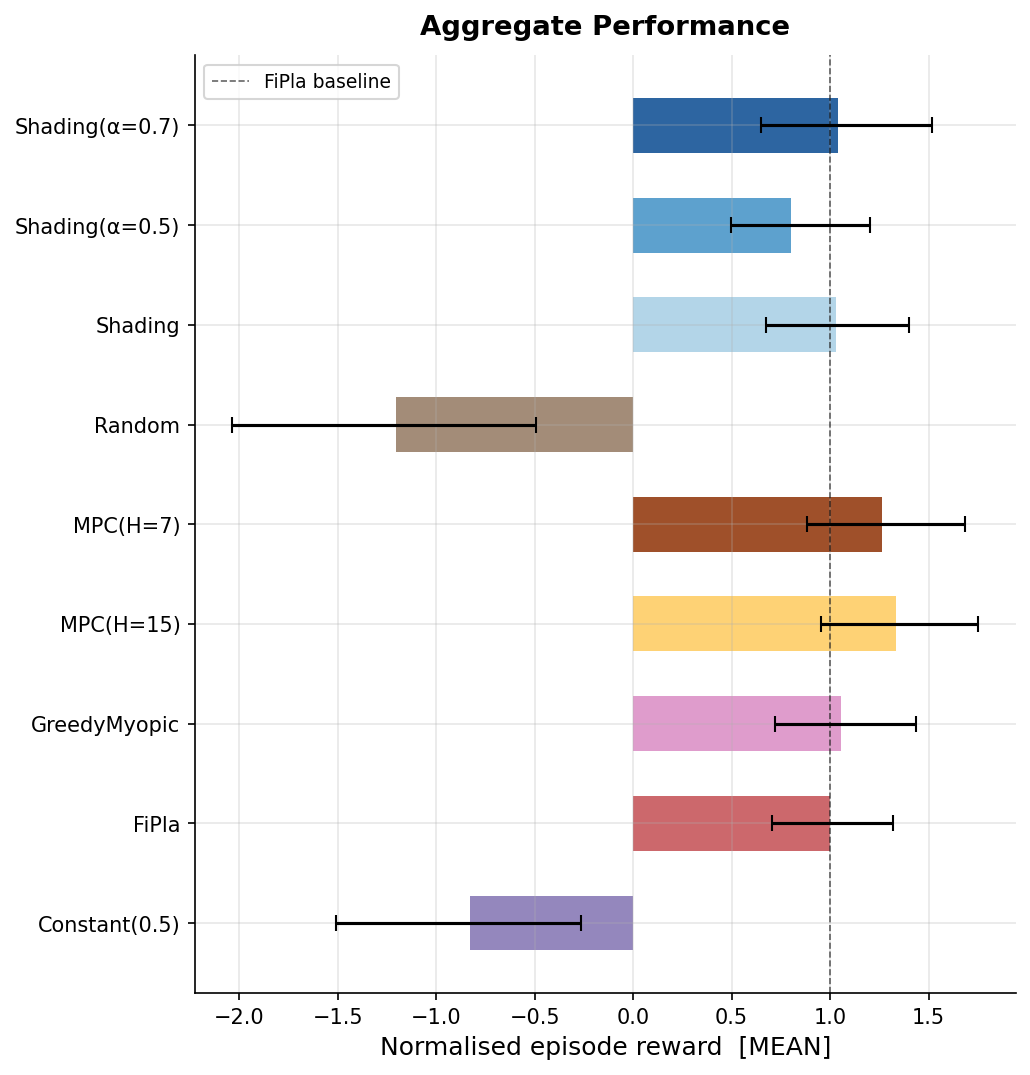

In [36]:
_ = plots.plot_aggregate_metrics(scores, metric="mean")

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance across seeds.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/performance_profiles.pdf


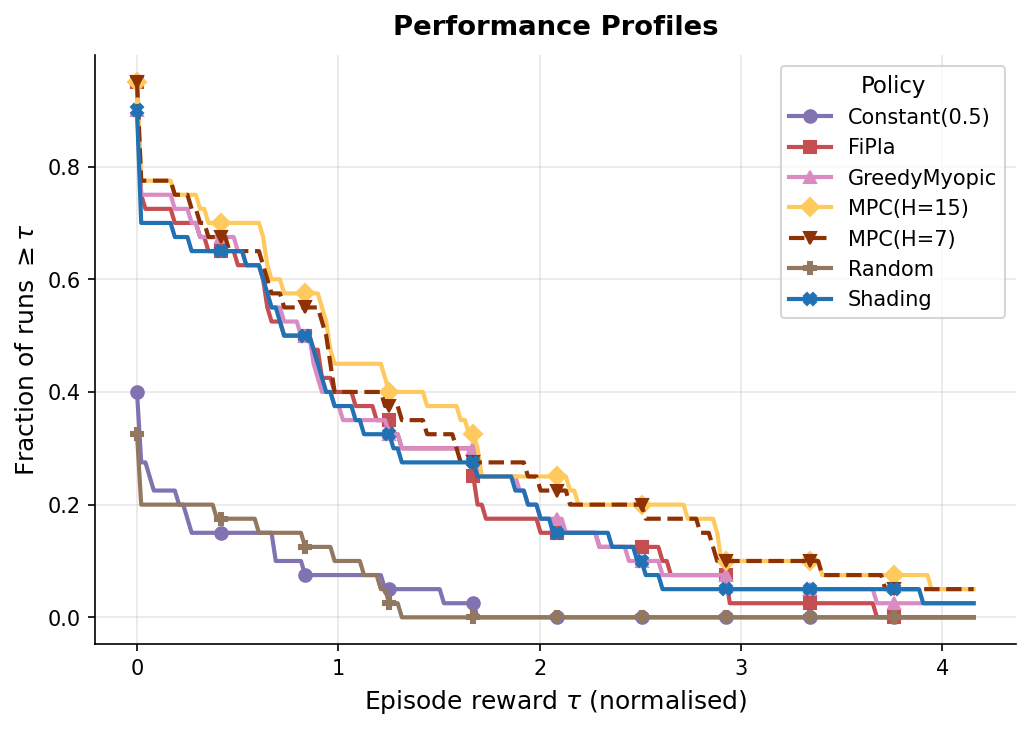

In [7]:
_ = plots.plot_performance_profiles(scores)

### Cumulative reward over time

Mean cumulative reward as a function of auction step, averaged over 30 seeds. Shaded bands are ±1 standard deviation.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/cumulative_reward.pdf


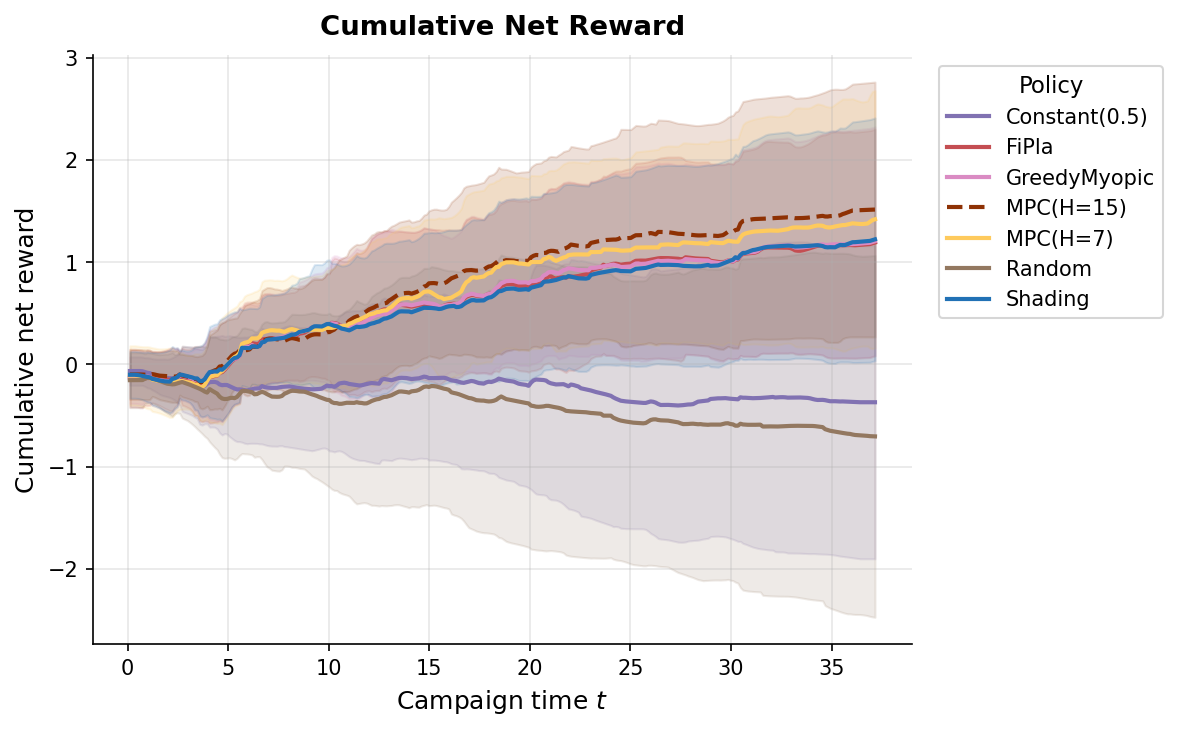

In [8]:
_ = plots.plot_cumulative_reward(final_df)

### Episode reward distribution

Distribution of total episode reward across 30 seeds for each policy (violin + individual seed points).

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:344: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/reward_distribution.pdf


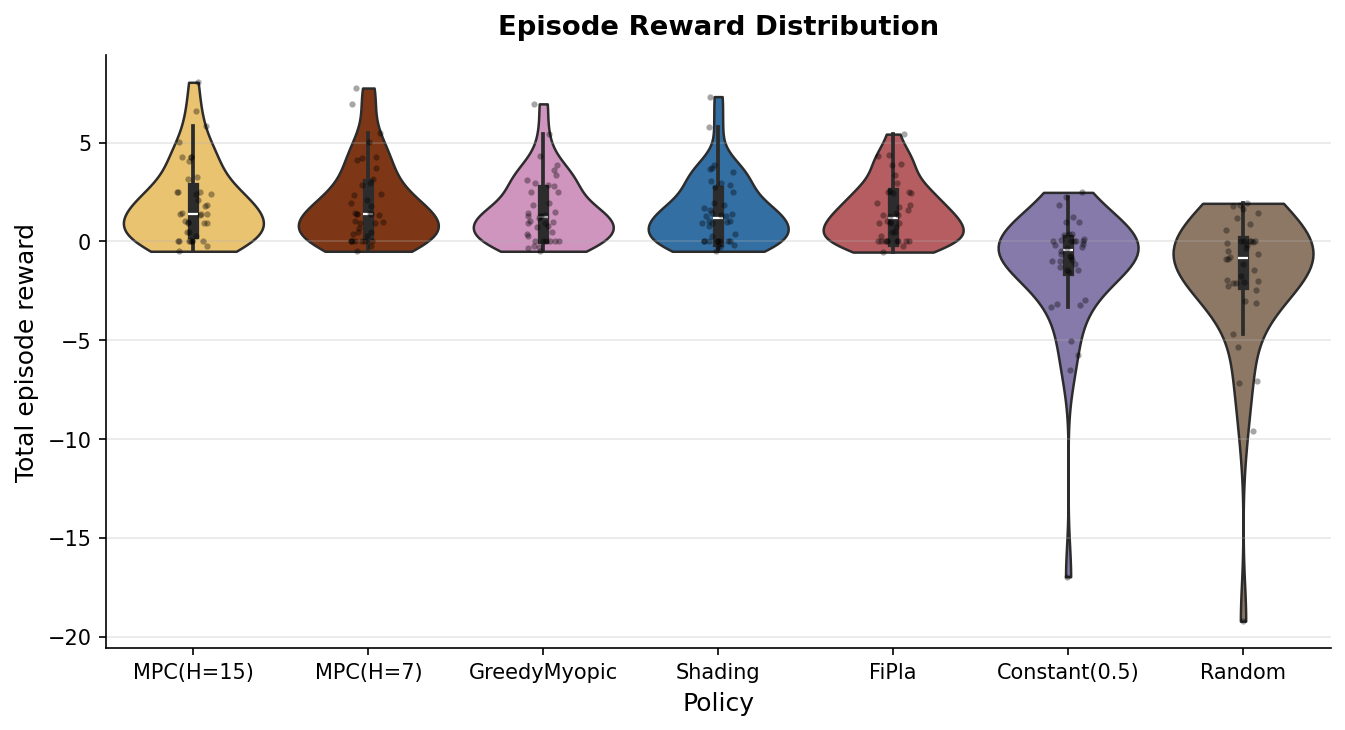

In [9]:
_ = plots.plot_reward_distribution(final_df)

### Training curves

Mean episodic reward during training (from TensorBoard logs), smoothed over a rolling window. One curve per RL algorithm; baselines are not trained so they do not appear here.

  [WARNING] Tag 'eval/mean_reward' not found for SAC
  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/training_curves.pdf


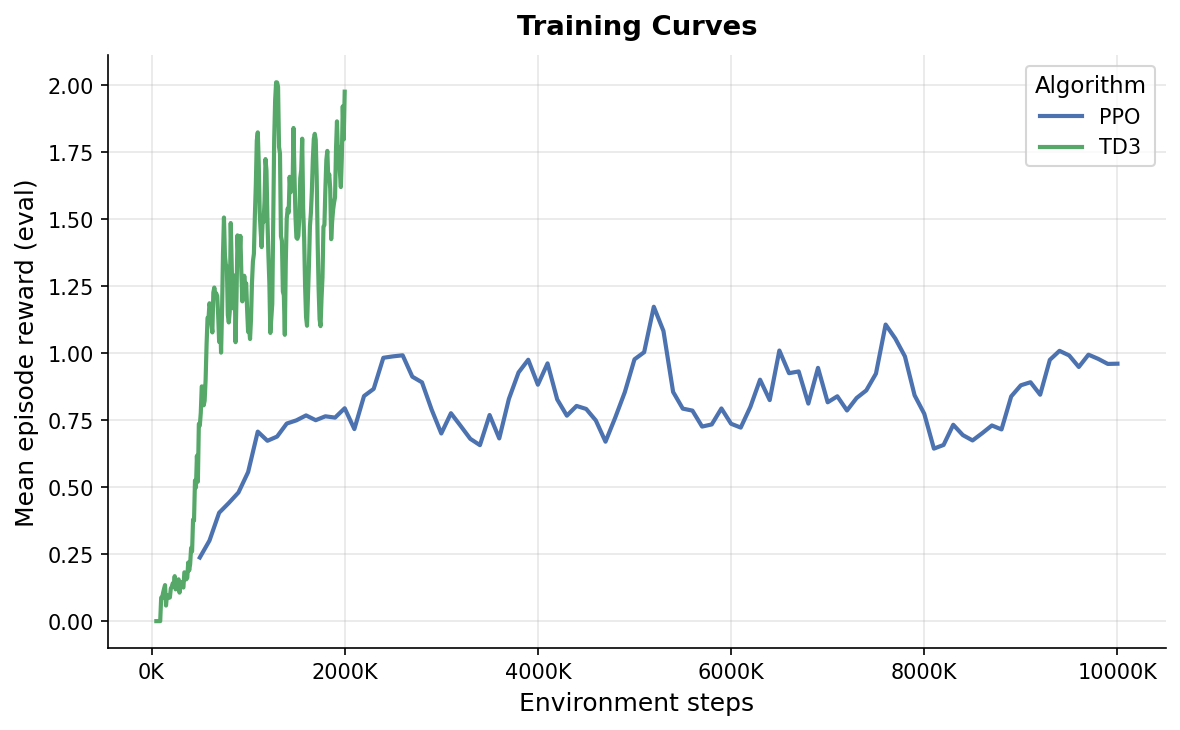

In [12]:
_ = plots.plot_training_curves()

### Context dynamics

Evolution of the context signal `ctx` over auction steps, averaged across seeds. Illustrates how the survival/saturation value kernel erodes the display value as the campaign progresses.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/context_dynamics.pdf


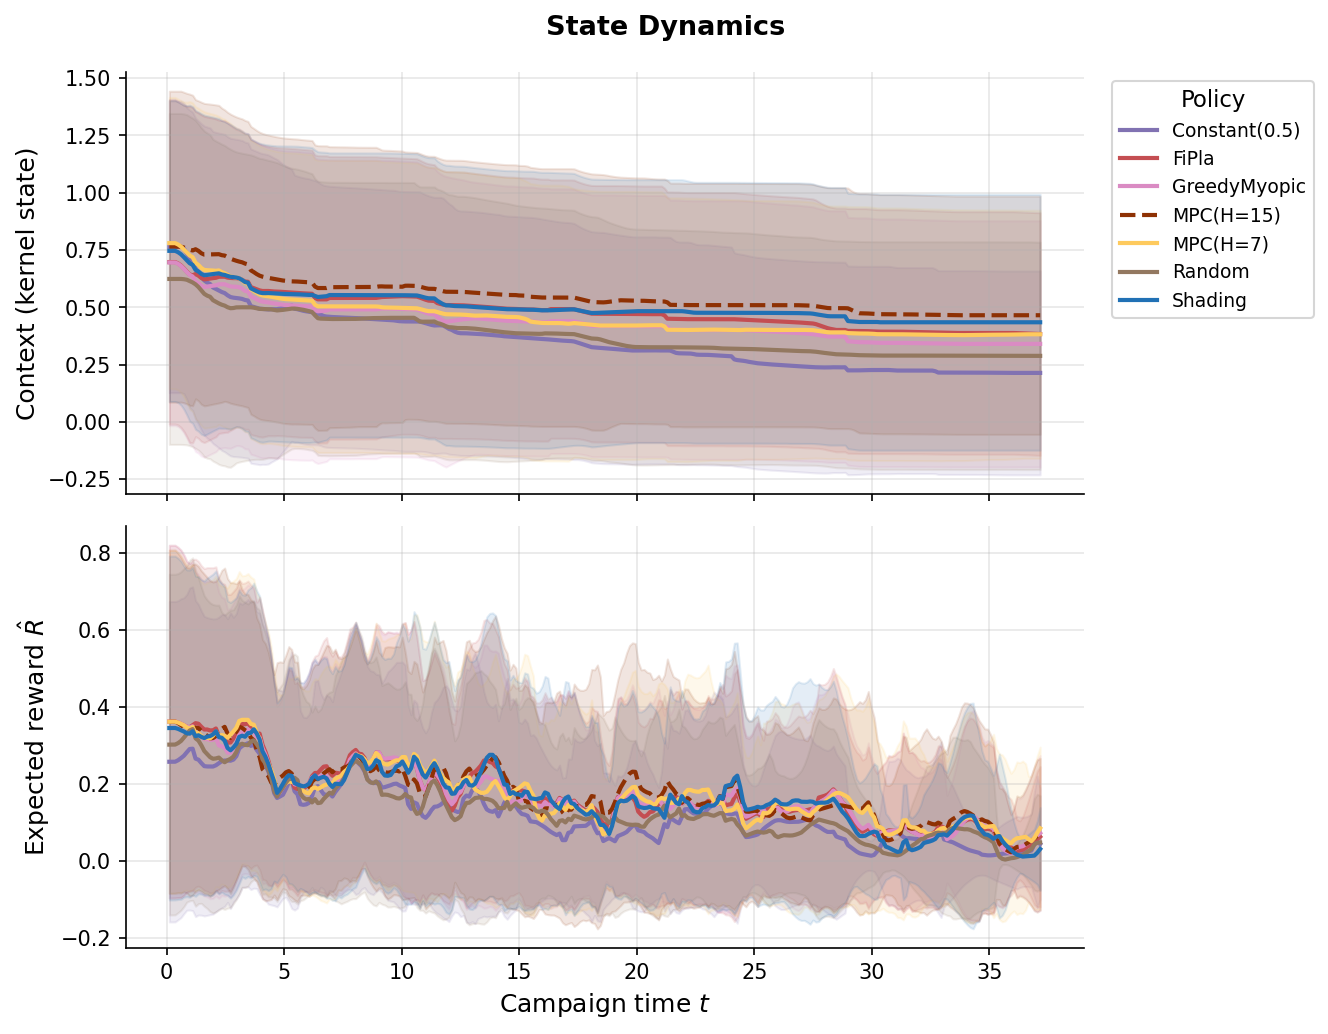

In [10]:
_ = plots.plot_context_dynamics(final_df)

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`). Shows how well each policy aligns bids with true value.

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:534: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/bid_distributions.pdf


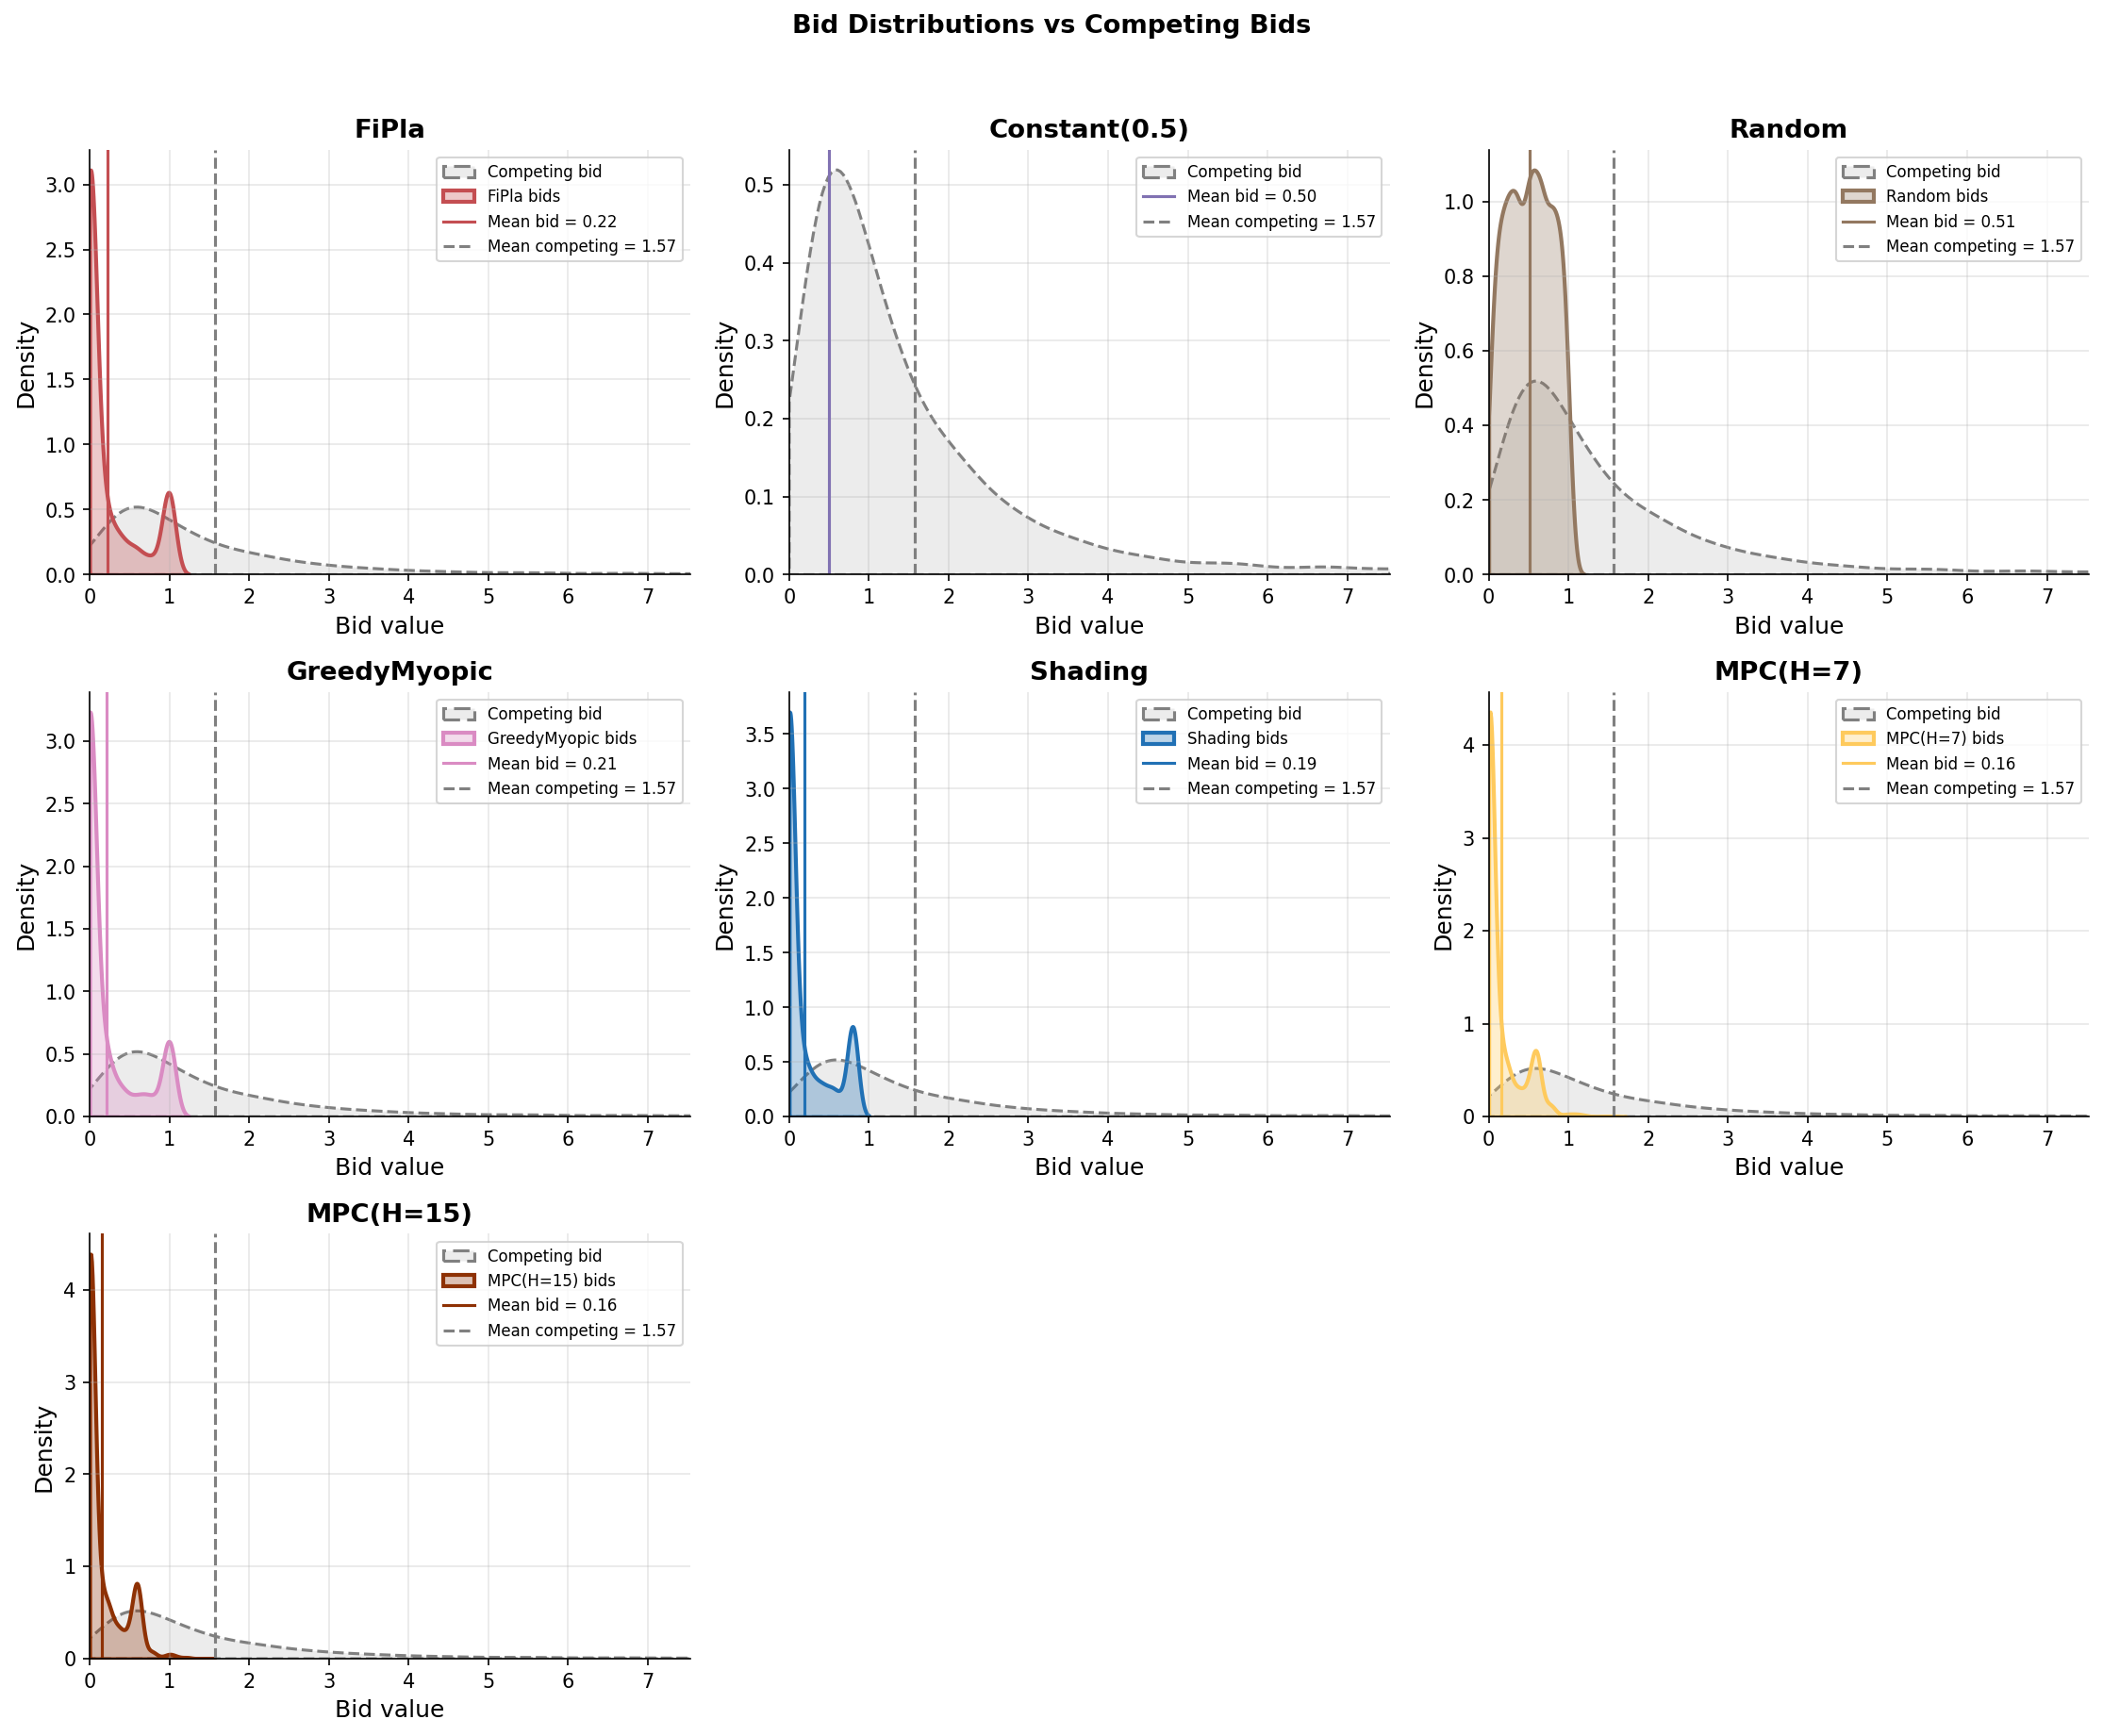

In [13]:
_ = plots.plot_bid_distributions(final_df)

### Win rate

Fraction of auctions won per policy, averaged over seeds. Under second-price rules the truthful bid (FiPla) is optimal, so its win rate serves as the upper reference.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/win_rate.pdf


/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:576: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",


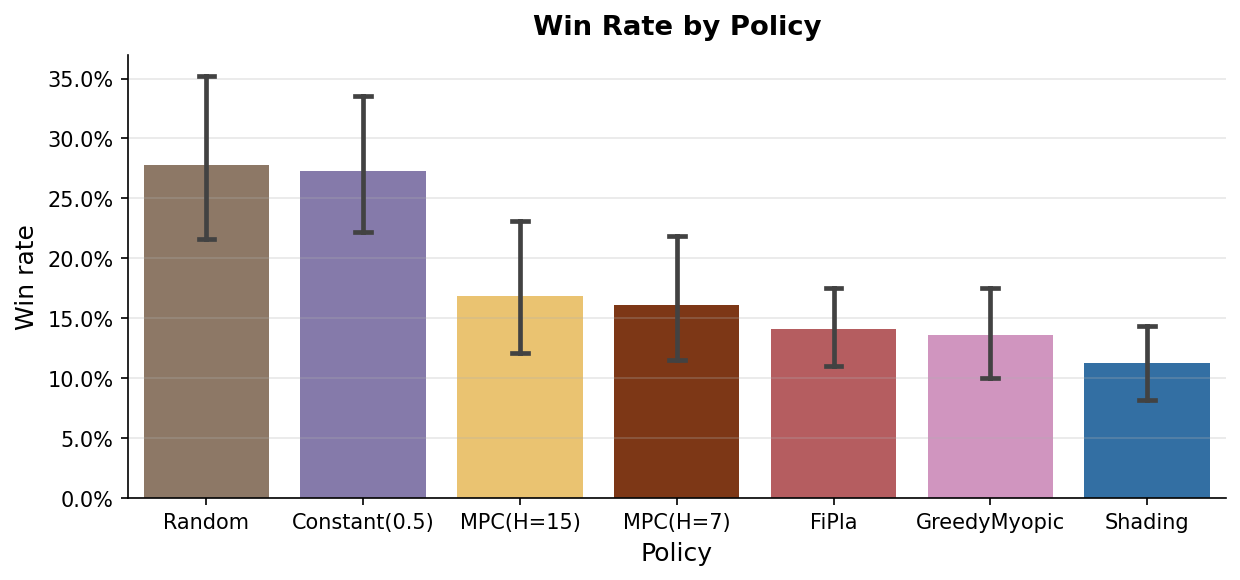

In [14]:
_ = plots.plot_win_rate(final_df)

### Full benchmark summary

Combined figure reported in the paper, aggregating aggregate metrics, performance profiles, and reward distributions into a single panel.

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:697: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/full_benchmark.pdf


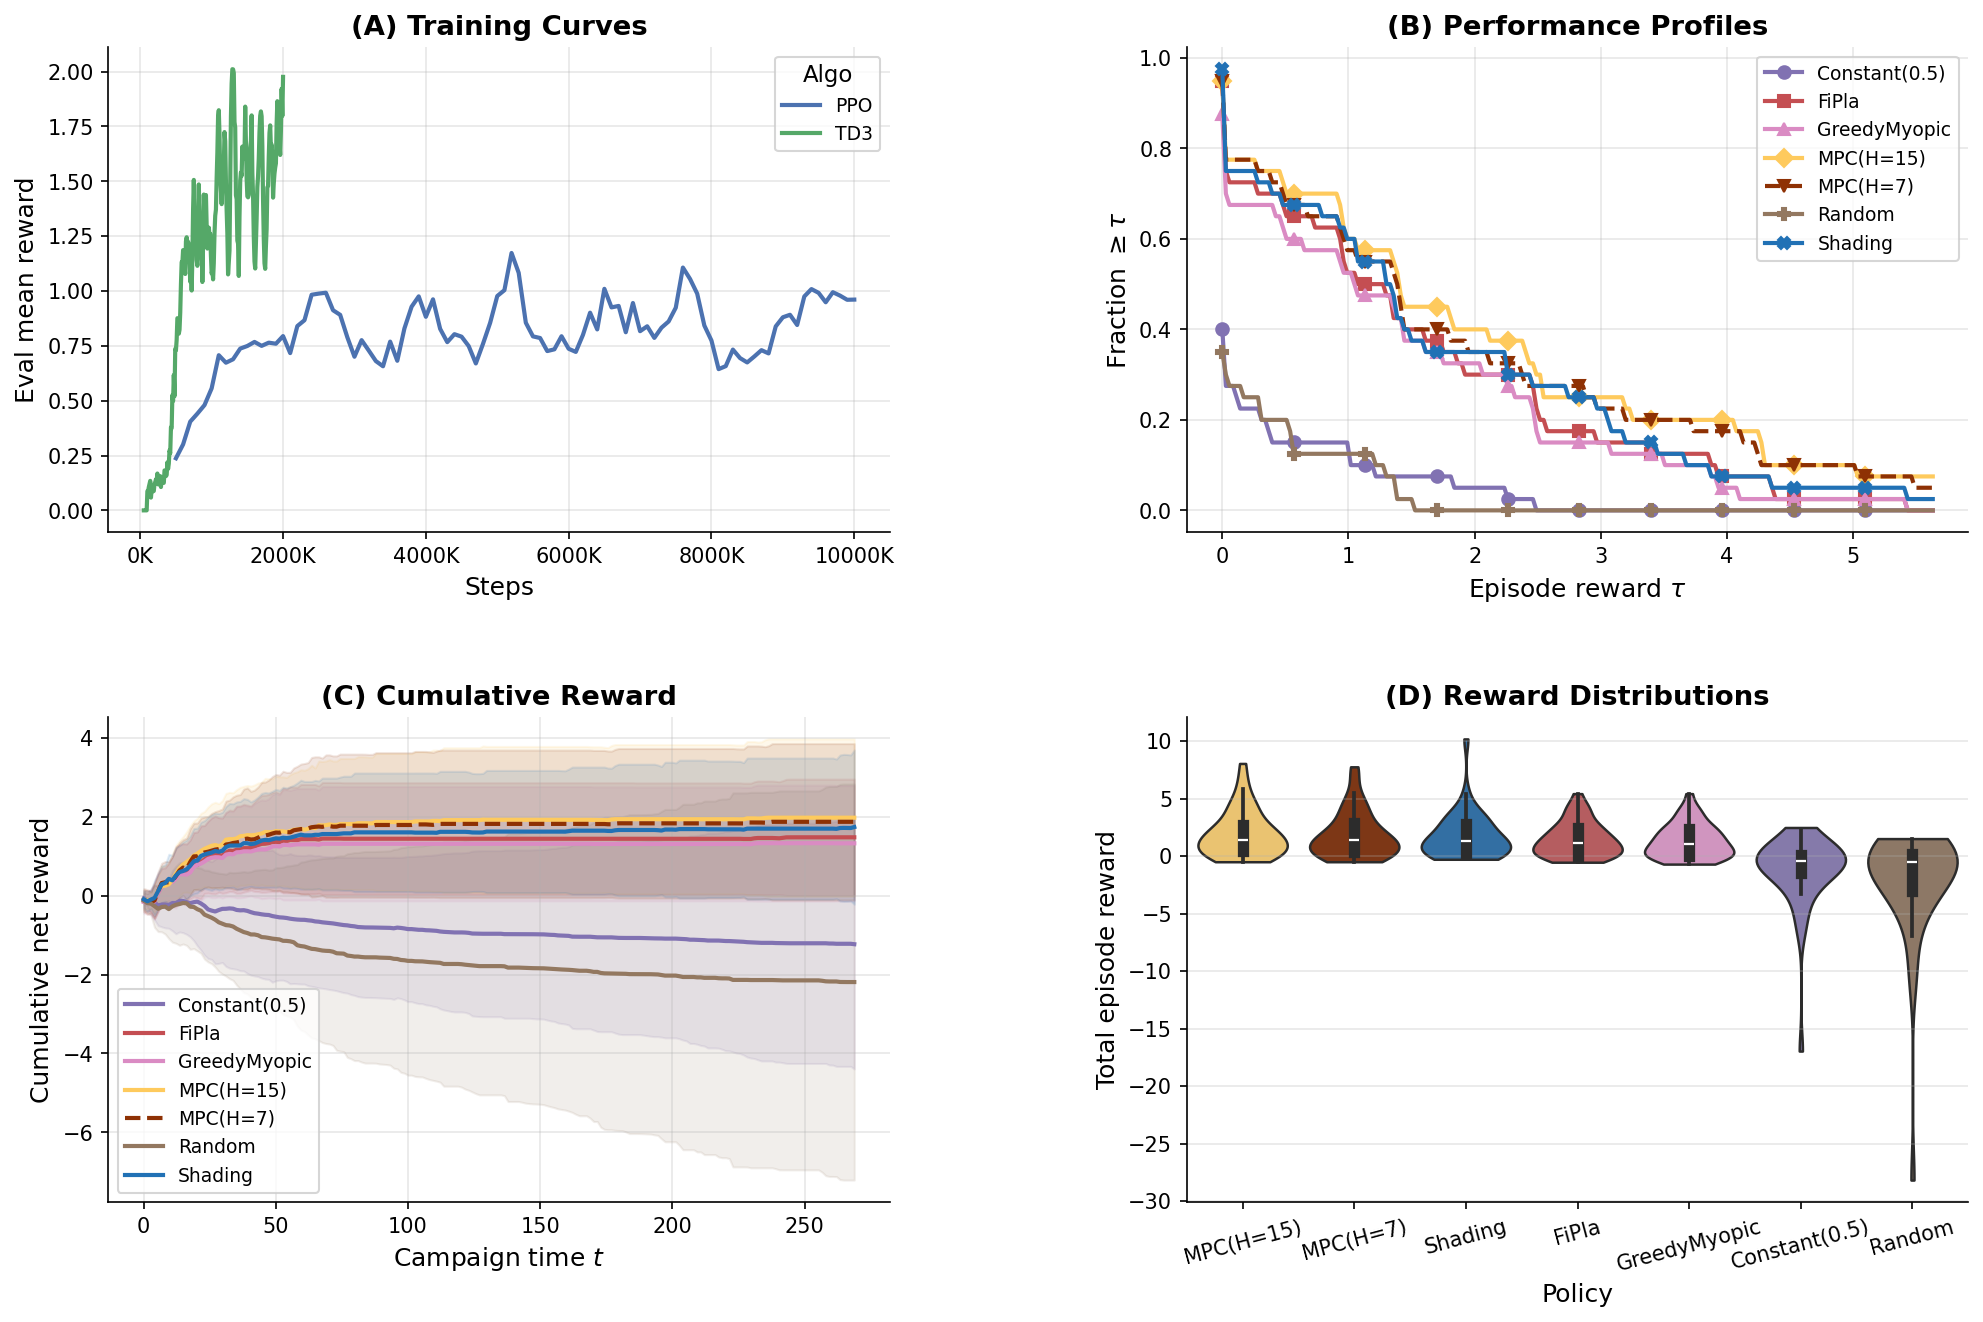

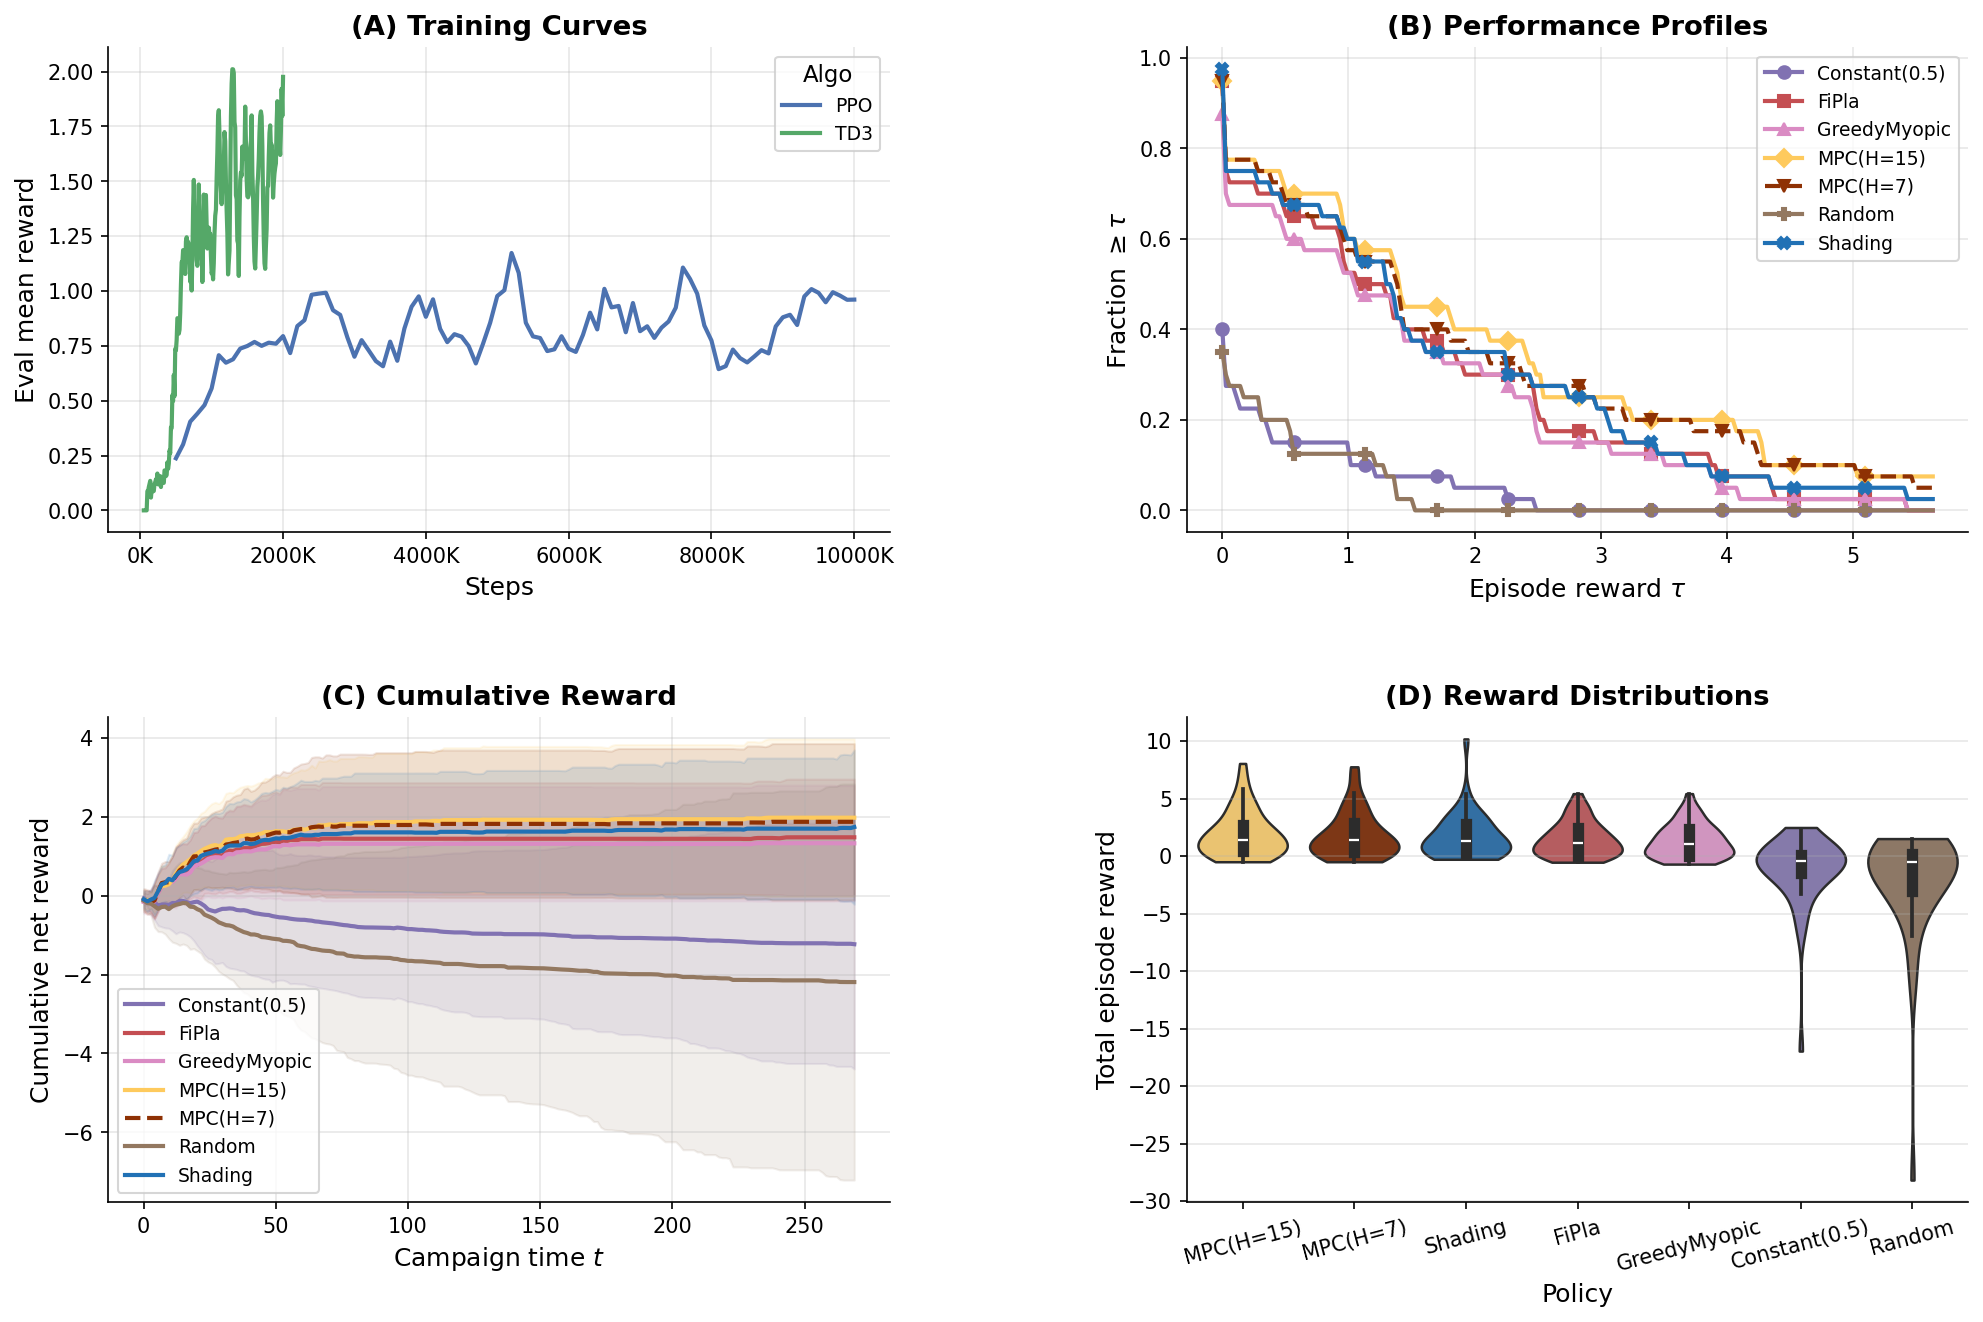

In [15]:
plots.plot_full_benchmark(final_df, scores)

  Loaded MLPValuationHead ← models/mlp_valuation_head/survival-second-price-exponential.pt  (hidden_dims=[64, 64], input_dim=12)
  Evaluating MPC(H=7) (30 seeds) …


Evaluating MPC(H=7):   0%|          | 0/30 [00:00<?, ?seed/s]

Evaluating MPC(H=7): 100%|██████████| 30/30 [00:40<00:00,  1.34s/seed]


  Evaluating MPC(H=15) (30 seeds) …


Evaluating MPC(H=15): 100%|██████████| 30/30 [01:15<00:00,  2.50s/seed]
/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:755: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="policy", y="alpha*", palette=palette,


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/mpc_alpha_distribution.pdf


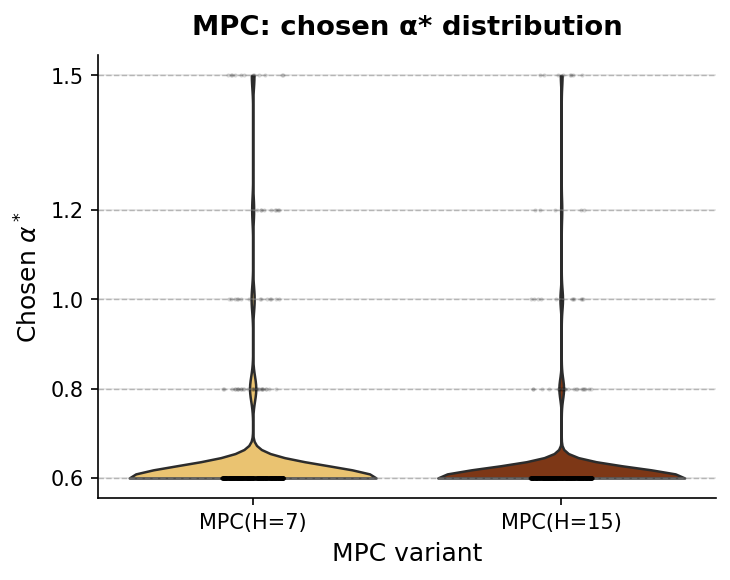

In [16]:
from benchmark.evaluate import EvalConfig, get_simulation_policies, benchmark

cfg = EvalConfig(
    include_mpc=True,
    mpc_model_paths=["models/mlp_valuation_head/survival-second-price-exponential.pt"],
    mpc_planning_horizons=[7.0, 15.0],
)
sim_policies = get_simulation_policies(cfg)
benchmark(sim_policies, cfg)

mpc = {k: v for k, v in sim_policies.items() if hasattr(v, "alpha_log")}
_ = plots.plot_mpc_alpha_distribution(mpc)